In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min
import nltk
from nltk.util import ngrams
from nltk import pos_tag
from nltk.corpus import stopwords
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM, AutoModel, AutoTokenizer
from transformers import XLMRobertaTokenizer, XLMRobertaForCausalLM
import os 

In [2]:
nltk.download('punkt')
nltk.download('averaged_perceptron_tagger')
nltk.download('stopwords')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\G34371231\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package averaged_perceptron_tagger to
[nltk_data]     C:\Users\G34371231\AppData\Roaming\nltk_data...
[nltk_data]   Package averaged_perceptron_tagger is already up-to-
[nltk_data]       date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\G34371231\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


True

In [27]:
path = os.getcwd() #path should be Evaluation folder
parent = os.path.join(path, os.pardir) #parent directory
memo_dataset_path = os.path.join(parent, "Data/Memo_Dataset.csv")
df = pd.read_csv(memo_dataset_path)
df['Trigger'] = df['Trigger'].astype(int)
min_count = df['Trigger'].value_counts().min()
df= (
    df.groupby('Trigger', group_keys=False)
    .apply(lambda x: x.sample(min_count, random_state=42))
    .reset_index(drop=True)
)

C:\Users\G34371231\AppData\Local\Temp\ipykernel_25940\2689029691.py:9: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda x: x.sample(min_count, random_state=42))


In [28]:
LANGUAGE = 'english' #english, arabic, both

In [29]:
if LANGUAGE == 'english':
    df['text'] = df['Question_eng']
elif LANGUAGE == 'arabic':
    df['text'] = df['Question']
else:
    df['text'] = df['Question_eng'] + ' ||| ' + df['Question']

print("Dataset shape:", df.shape)
print("Class distribution:\n", df['Trigger'].value_counts(normalize=True))

Dataset shape: (10910, 4)
Class distribution:
 Trigger
0    0.5
1    0.5
Name: proportion, dtype: float64


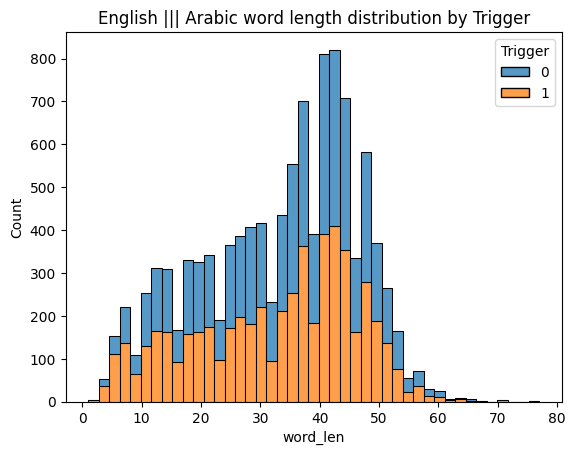

In [30]:
# lengths
df['char_len'] = df['text'].str.len()
df['word_len'] = df['text'].str.split().apply(len)

sns.histplot(df, x='word_len', hue='Trigger', multiple='stack')
plt.title('English ||| Arabic word length distribution by Trigger')
plt.show()

Top 1-grams overall:
[('pain', np.int64(3530)), ('old', np.int64(1980)), ('years', np.int64(1687)), ('feel', np.int64(1639)), ('suffer', np.int64(1572)), ('normal', np.int64(1468)), ('days', np.int64(1336)), ('doctor', np.int64(1289)), ('does', np.int64(1247)), ('blood', np.int64(1232)), ('peace', np.int64(1090)), ('months', np.int64(1066)), ('period', np.int64(1050)), ('left', np.int64(968)), ('treatment', np.int64(921)), ('ago', np.int64(905)), ('time', np.int64(862)), ('month', np.int64(859)), ('day', np.int64(838)), ('did', np.int64(801))]
Top 1-grams for triggers:
[('pain', np.int64(2237)), ('suffer', np.int64(933)), ('feel', np.int64(878)), ('old', np.int64(827)), ('years', np.int64(789)), ('doctor', np.int64(639)), ('treatment', np.int64(583)), ('does', np.int64(556)), ('blood', np.int64(556)), ('days', np.int64(555)), ('severe', np.int64(543)), ('peace', np.int64(497)), ('left', np.int64(496)), ('months', np.int64(495)), ('ago', np.int64(461)), ('time', np.int64(447)), ('right'

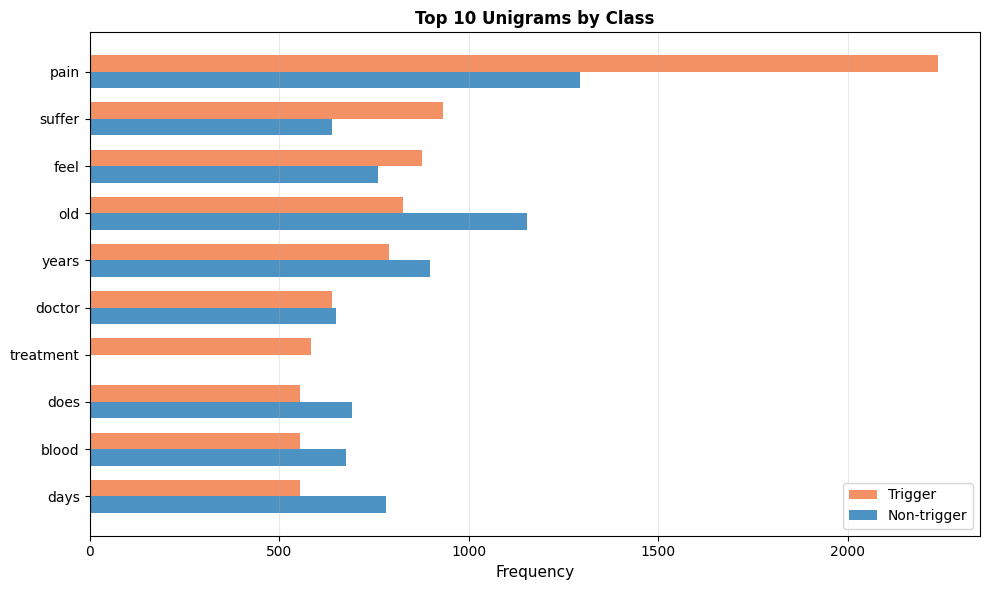

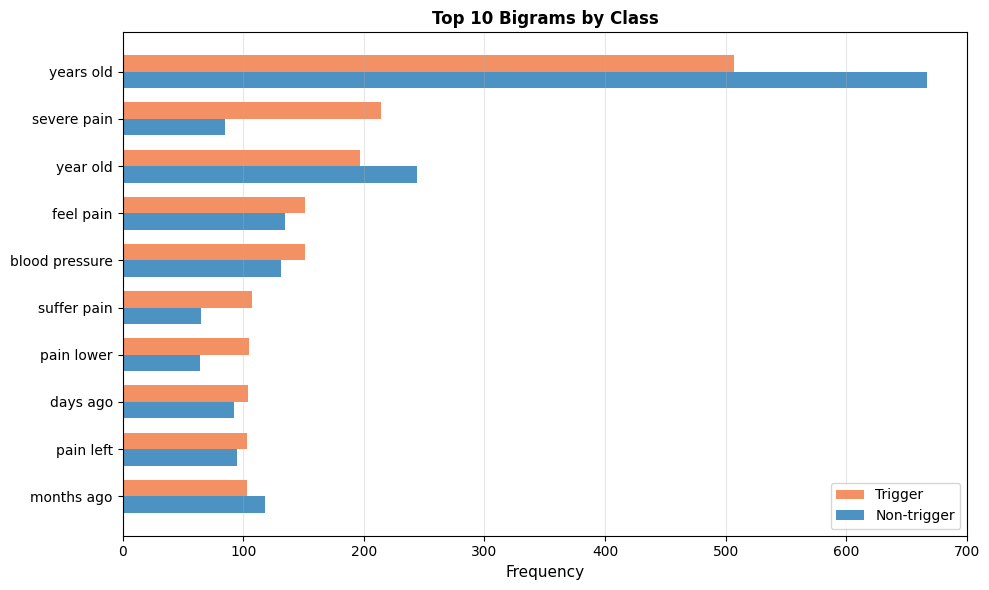

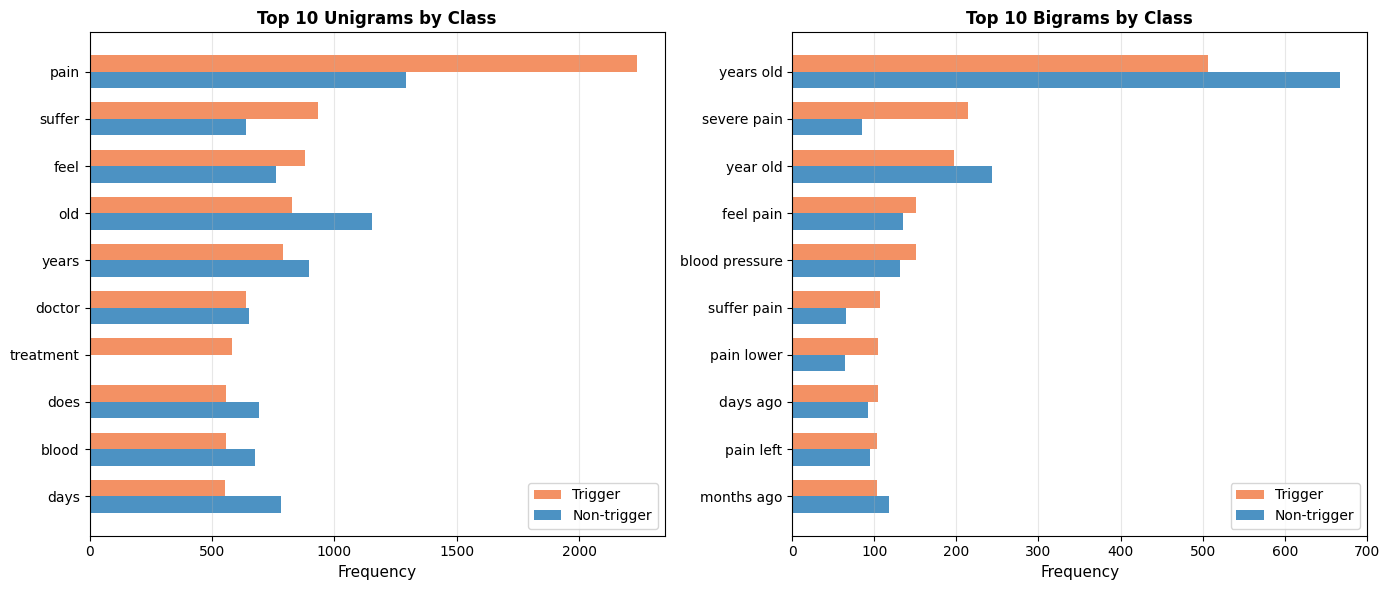

In [31]:
def get_top_ngrams(texts, n=1, top_k=20): #ngram analysis
    vec = CountVectorizer(ngram_range=(n,n), stop_words='english' if LANGUAGE in ['english','both'] else None)
    X = vec.fit_transform(texts)
    sum_words = X.sum(axis=0)
    words_freq = [(word, sum_words[0, idx]) for word, idx in vec.vocabulary_.items()]
    words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)
    return words_freq[:top_k]

trigger_texts = df[df['Trigger']==1]['text']
non_trigger_texts = df[df['Trigger']==0]['text']

ngram_data = {}
for n in [1,2,3]:
    print(f"Top {n}-grams overall:")
    overall = get_top_ngrams(df['text'], n)
    print(overall)
    
    print(f"Top {n}-grams for triggers:")
    triggers = get_top_ngrams(trigger_texts, n)
    print(triggers)
    
    print(f"Top {n}-grams for non-triggers:")
    non_triggers = get_top_ngrams(non_trigger_texts, n)
    print(non_triggers)
    
    # Store for plotting
    ngram_data[n] = {
        'triggers': triggers,
        'non_triggers': non_triggers
    }


def plot_ngram_comparison(trigger_ngrams, nontrigger_ngrams, n, top_k=20, save_path=None):
    #horizontal bar chart comparing trigger vs non-trigger n-grams
    top_trigger = trigger_ngrams[:top_k]
    trigger_words = [w for w, _ in top_trigger]
    trigger_counts = [c for _, c in top_trigger]
    
    #counts for the same words from non-triggers
    nontrigger_dict = dict(nontrigger_ngrams)
    nontrigger_counts = [nontrigger_dict.get(w, 0) for w in trigger_words]
    
    fig, ax = plt.subplots(figsize=(10, 6))
    
    x = np.arange(len(trigger_words))
    width = 0.35
    
    bars1 = ax.barh(x - width/2, trigger_counts, width, 
                    label='Trigger', color='#f1763d', alpha=0.8)
    bars2 = ax.barh(x + width/2, nontrigger_counts, width, 
                    label='Non-trigger', color='#1f77b4', alpha=0.8)
    
    ax.set_yticks(x)
    ax.set_yticklabels(trigger_words)
    ax.set_xlabel('Frequency', fontsize=11)
    
    ngram_name = {1: 'Unigrams', 2: 'Bigrams', 3: 'Trigrams'}
    ax.set_title(f'Top {top_k} {ngram_name[n]} by Class', fontsize=12, fontweight='bold')
    ax.legend(loc='lower right')
    ax.invert_yaxis()
    ax.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved plot to {save_path}")
    
    return fig

#individual plots for 1-grams and 2-grams
fig1 = plot_ngram_comparison(
    ngram_data[1]['triggers'], 
    ngram_data[1]['non_triggers'], 
    n=1, 
    top_k=10,
    save_path='unigram_comparison.png'
)

fig2 = plot_ngram_comparison(
    ngram_data[2]['triggers'], 
    ngram_data[2]['non_triggers'], 
    n=2, 
    top_k=10,
    save_path='bigram_comparison.png'
)

#combined plot with both 1-grams and 2-grams side by side
def plot_combined_ngrams(ngram_data, top_k=20, save_path=None):
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))
    
    for idx, n in enumerate([1, 2]):
        ax = axes[idx]
        
        # Get data
        top_trigger = ngram_data[n]['triggers'][:top_k]
        trigger_words = [w for w, _ in top_trigger]
        trigger_counts = [c for _, c in top_trigger]
        
        nontrigger_dict = dict(ngram_data[n]['non_triggers'])
        nontrigger_counts = [nontrigger_dict.get(w, 0) for w in trigger_words]
        
        # Plot
        x = np.arange(len(trigger_words))
        width = 0.35
        
        bars1 = ax.barh(x - width/2, trigger_counts, width, 
                        label='Trigger', color='#f1763d', alpha=0.8)
        bars2 = ax.barh(x + width/2, nontrigger_counts, width, 
                        label='Non-trigger', color='#1f77b4', alpha=0.8)
        
        ax.set_yticks(x)
        ax.set_yticklabels(trigger_words)
        ax.set_xlabel('Frequency', fontsize=11)
        
        ngram_name = {1: 'Unigrams', 2: 'Bigrams'}
        ax.set_title(f'Top {top_k} {ngram_name[n]} by Class', 
                     fontsize=12, fontweight='bold')
        ax.legend(loc='lower right')
        ax.invert_yaxis()
        ax.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    
    if save_path:
        plt.savefig(save_path, dpi=300, bbox_inches='tight')
        print(f"Saved combined plot to {save_path}")
    
    return fig

# Create combined plot
fig_combined = plot_combined_ngrams(
    ngram_data, 
    top_k=10, 
    save_path='ngram_comparison_combined.png'
)

plt.show()


Saved trigger plot to unigram_1gram_trigger.png
Saved non-trigger plot to unigram_1gram_nontrigger.png
Saved trigger plot to bigram_2gram_trigger.png
Saved non-trigger plot to bigram_2gram_nontrigger.png
Saved trigger plot to trigram_3gram_trigger.png
Saved non-trigger plot to trigram_3gram_nontrigger.png


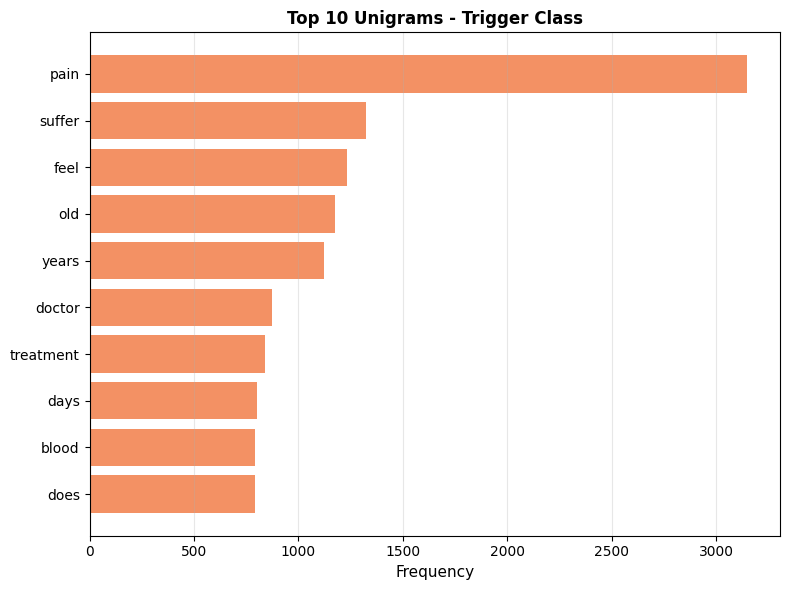

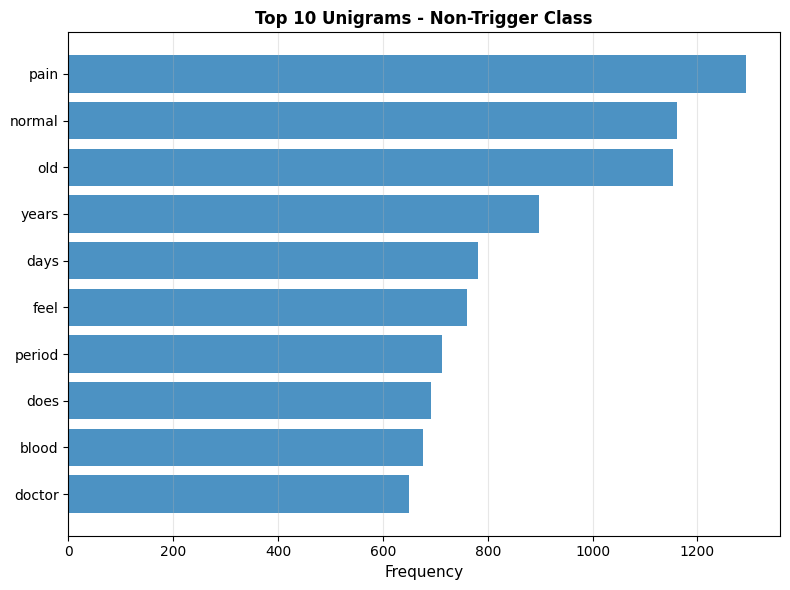

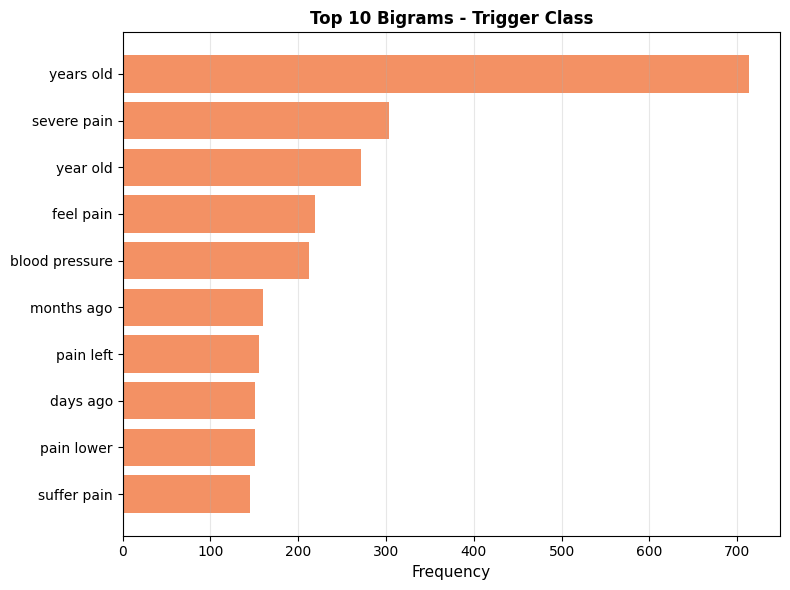

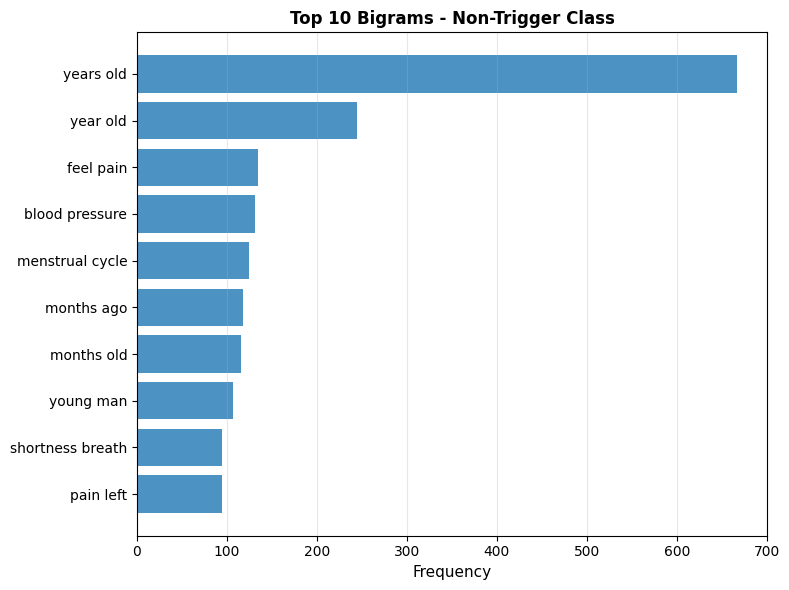

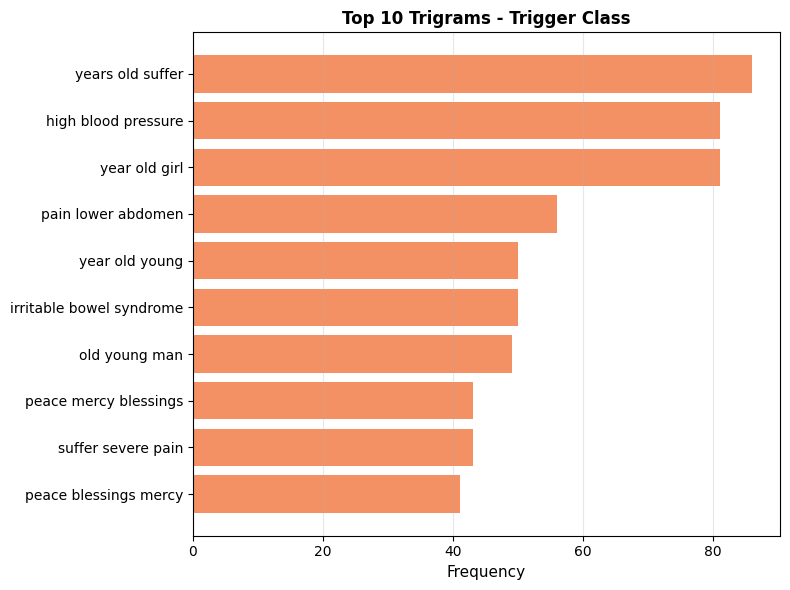

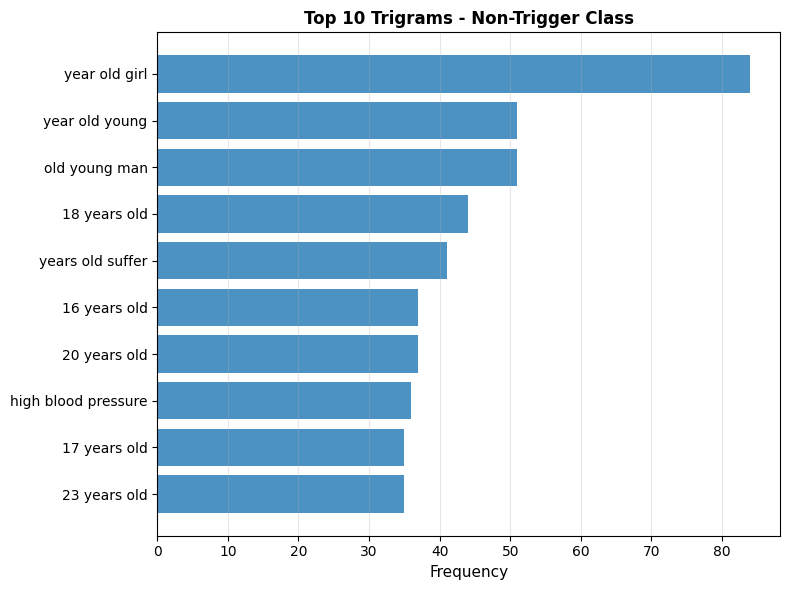

In [22]:
def plot_ngrams_by_class(trigger_ngrams, nontrigger_ngrams, n, top_k=10, save_prefix='ngrams'):
    #separate horizontal bar charts for trigger and non-trigger classes
    ngram_name = {1: 'Unigrams', 2: 'Bigrams', 3: 'Trigrams'}
    
    #Trigger class
    fig1, ax1 = plt.subplots(figsize=(8, 6))
    
    top_trigger = trigger_ngrams[:top_k]
    trigger_words = [w for w, _ in top_trigger]
    trigger_counts = [c for _, c in top_trigger]
    
    y_pos = np.arange(len(trigger_words))
    bars1 = ax1.barh(y_pos, trigger_counts, color='#f1763d', alpha=0.8)
    
    ax1.set_yticks(y_pos)
    ax1.set_yticklabels(trigger_words)
    ax1.set_xlabel('Frequency', fontsize=11)
    ax1.set_title(f'Top {top_k} {ngram_name[n]} - Trigger Class', 
                  fontsize=12, fontweight='bold')
    ax1.invert_yaxis()
    ax1.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    save_path1 = f'{save_prefix}_{n}gram_trigger.png'
    plt.savefig(save_path1, dpi=300, bbox_inches='tight')
    print(f"Saved trigger plot to {save_path1}")
    
    #Non-trigger class
    fig2, ax2 = plt.subplots(figsize=(8, 6))
    
    top_nontrigger = nontrigger_ngrams[:top_k]
    nontrigger_words = [w for w, _ in top_nontrigger]
    nontrigger_counts = [c for _, c in top_nontrigger]
    
    y_pos = np.arange(len(nontrigger_words))
    bars2 = ax2.barh(y_pos, nontrigger_counts, color='#1f77b4', alpha=0.8)
    
    ax2.set_yticks(y_pos)
    ax2.set_yticklabels(nontrigger_words)
    ax2.set_xlabel('Frequency', fontsize=11)
    ax2.set_title(f'Top {top_k} {ngram_name[n]} - Non-Trigger Class', 
                  fontsize=12, fontweight='bold')
    ax2.invert_yaxis()
    ax2.grid(axis='x', alpha=0.3)
    
    plt.tight_layout()
    save_path2 = f'{save_prefix}_{n}gram_nontrigger.png'
    plt.savefig(save_path2, dpi=300, bbox_inches='tight')
    print(f"Saved non-trigger plot to {save_path2}")
    
    return fig1, fig2

fig_trigger_1, fig_nontrigger_1 = plot_ngrams_by_class(
    ngram_data[1]['triggers'], 
    ngram_data[1]['non_triggers'], 
    n=1, 
    top_k=10,
    save_prefix='unigram'
)

fig_trigger_2, fig_nontrigger_2 = plot_ngrams_by_class(
    ngram_data[2]['triggers'], 
    ngram_data[2]['non_triggers'], 
    n=2, 
    top_k=10,
    save_prefix='bigram'
)

fig_trigger_3, fig_nontrigger_3 = plot_ngrams_by_class(
    ngram_data[3]['triggers'], 
    ngram_data[3]['non_triggers'], 
    n=3, 
    top_k=10,
    save_prefix='trigram'
)

plt.show()

In [95]:
def compute_entropy(texts):
    tokens = ' '.join(texts).split()
    counts = np.array(list(Counter(tokens).values()))
    probs = counts / counts.sum()
    return -np.sum(probs * np.log2(probs))

entropy_trigger = compute_entropy(trigger_texts)
entropy_nontrigger = compute_entropy(non_trigger_texts)
print("Entropy Trigger:", entropy_trigger)
print("Entropy Non-Trigger:", entropy_nontrigger)

Entropy Trigger: 11.8800683057194
Entropy Non-Trigger: 11.71630591442351


In [96]:
tokenizer = XLMRobertaTokenizer.from_pretrained("xlm-roberta-base")#AutoTokenizer.from_pretrained('gpt-2'')
model = XLMRobertaForCausalLM.from_pretrained("xlm-roberta-base")#model = AutoModelForCausalLM.from_pretrained(lm_model_name)
model.eval()

def compute_ppl(texts):
    ppl_list = []
    for text in texts:
        encodings = tokenizer(text, return_tensors='pt')
        with torch.no_grad():
            outputs = model(**encodings, labels=encodings['input_ids'])
            loss = outputs.loss
        ppl = torch.exp(loss).item()
        ppl_list.append(ppl)
    return np.mean(ppl_list)

if LANGUAGE in ['english','both']:
    ppl_trigger = compute_ppl(trigger_texts[:50])  # sample to save time
    ppl_nontrigger = compute_ppl(non_trigger_texts[:50])
    print("Perplexity Trigger:", ppl_trigger)
    print("Perplexity Non-Trigger:", ppl_nontrigger)

If you want to use `XLMRobertaLMHeadModel` as a standalone, add `is_decoder=True.`


In [97]:
#pos tags english
if LANGUAGE in ['english','both']:
    trigger_tokens = [word for sent in trigger_texts for word in nltk.word_tokenize(sent)]
    nontrigger_tokens = [word for sent in non_trigger_texts for word in nltk.word_tokenize(sent)]
    
    trigger_pos = [pos for word,pos in pos_tag(trigger_tokens)]
    nontrigger_pos = [pos for word,pos in pos_tag(nontrigger_tokens)]
    
    trigger_pos_counts = Counter(trigger_pos)
    nontrigger_pos_counts = Counter(nontrigger_pos)
    
    print("Top POS Trigger:", trigger_pos_counts.most_common(10))
    print("Top POS Non-Trigger:", nontrigger_pos_counts.most_common(10))

In [98]:
from transformers import AutoTokenizer, AutoModel
import torch
import numpy as np

model_name = "xlm-roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_name)
model = AutoModel.from_pretrained(model_name)
model.eval()

def embed_xlmr(texts):
    embeddings = []
    for text in texts:
        encoded = tokenizer(text, return_tensors="pt", truncation=True, padding=True, max_length=256)
        with torch.no_grad():
            output = model(**encoded)

        # Mean pooling
        last_hidden = output.last_hidden_state  # (1, seq_len, hidden)
        mask = encoded["attention_mask"].unsqueeze(-1)  # (1, seq_len, 1)
        masked_hidden = last_hidden * mask
        pooled = masked_hidden.sum(dim=1) / mask.sum(dim=1)
        embeddings.append(pooled.squeeze().numpy())
    return np.vstack(embeddings)




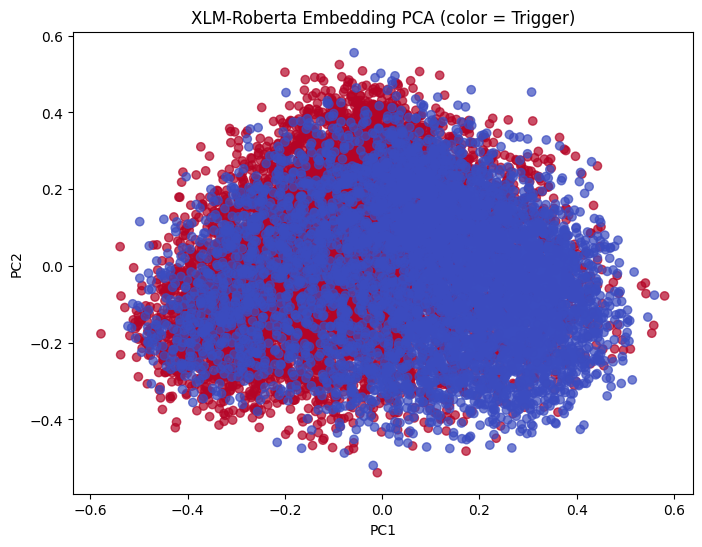

In [99]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)
emb_2d = pca.fit_transform(embeddings)

plt.figure(figsize=(8,6))
plt.scatter(emb_2d[:,0], emb_2d[:,1], 
            c=df["Trigger"], cmap="coolwarm", alpha=0.7)
plt.title("XLM-Roberta Embedding PCA (color = Trigger)")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()